Import Library

In [96]:
import gdown
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

Load Dataset

In [97]:
url = f"https://drive.google.com/file/d/1Z8fDjJYLVp_CCEbnbDdDizfo1WEgv71O/view?usp=sharing"

output = gdown.download(
    url,
    "dataset.csv",
    quiet=False,
    fuzzy=True
)

df = pd.read_csv("dataset.csv")
df.head()

Downloading...
From: https://drive.google.com/uc?id=1Z8fDjJYLVp_CCEbnbDdDizfo1WEgv71O
To: /content/dataset.csv
100%|██████████| 642k/642k [00:00<00:00, 74.8MB/s]


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [98]:
print("Dimensi dataset:", df.shape)
print("\nInformasi kolom:")
df.info()

Dimensi dataset: (6607, 20)

Informasi kolom:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Hours_Studied               6607 non-null   int64 
 1   Attendance                  6607 non-null   int64 
 2   Parental_Involvement        6607 non-null   object
 3   Access_to_Resources         6607 non-null   object
 4   Extracurricular_Activities  6607 non-null   object
 5   Sleep_Hours                 6607 non-null   int64 
 6   Previous_Scores             6607 non-null   int64 
 7   Motivation_Level            6607 non-null   object
 8   Internet_Access             6607 non-null   object
 9   Tutoring_Sessions           6607 non-null   int64 
 10  Family_Income               6607 non-null   object
 11  Teacher_Quality             6529 non-null   object
 12  School_Type                 6607 non-null   object
 13  Pe

Cek Missing Value

In [99]:
missing = pd.DataFrame({
    "Jumlah Missing": df.isna().sum(),
    "Persentase (%)": (df.isna().mean() * 100).round(2)
})
display(missing[missing["Jumlah Missing"] > 0])

,Jumlah Missing,Persentase (%)
Teacher_Quality,78,1.18
Parental_Education_Level,90,1.36
Distance_from_Home,67,1.01


Isi Missing Value dengan Modus

In [100]:
cols = ['Teacher_Quality', 'Parental_Education_Level', 'Distance_from_Home']
df[cols] = df[cols].fillna(df[cols].mode().iloc[0])

In [101]:
print("Total missing value di setiap kolom : \n", df.isna().sum())

Total missing value di setiap kolom : 
 Hours_Studied                 0
Attendance                    0
Parental_Involvement          0
Access_to_Resources           0
Extracurricular_Activities    0
Sleep_Hours                   0
Previous_Scores               0
Motivation_Level              0
Internet_Access               0
Tutoring_Sessions             0
Family_Income                 0
Teacher_Quality               0
School_Type                   0
Peer_Influence                0
Physical_Activity             0
Learning_Disabilities         0
Parental_Education_Level      0
Distance_from_Home            0
Gender                        0
Exam_Score                    0
dtype: int64


Cek Data Duplikat

In [102]:
print("Jumlah baris duplikat:", df.duplicated().sum())

Jumlah baris duplikat: 0


In [103]:
df = df.drop_duplicates().copy()
df = df.dropna(subset=["Exam_Score"]).copy()

In [104]:
df["Target"] = np.where(
    df["Exam_Score"] >= 68,
    1,
    -1
)

print("Distribusi kelas:")
print(df["Target"].value_counts().sort_index())

print("\nProporsi kelas:")
print(df["Target"].value_counts(normalize=True).sort_index())

Distribusi kelas:
Target
-1    3599
 1    3008
Name: count, dtype: int64

Proporsi kelas:
Target
-1    0.544725
 1    0.455275
Name: proportion, dtype: float64


In [105]:
X = df.drop(columns=["Exam_Score", "Target"])
y = df["Target"]

print("\nDimensi fitur:", X.shape)
print("Dimensi target:", y.shape)


Dimensi fitur: (6607, 19)
Dimensi target: (6607,)


In [106]:
class Perceptron:
    def __init__(self, eta=0.001, epochs=50):
        self.eta, self.epochs = eta, epochs
    def fit(self, X, y):
        self.w = np.zeros(X.shape[1]); self.b = 0.0   # inisialisasi nol
        self.errors_ = []
        for _ in range(self.epochs):
            n_err = 0
            for xi, yi in zip(X, y):
                yhat = np.dot(xi, self.w) + self.b
                if yhat >= 0:
                    yhat = 1
                else:
                    yhat = -1
                delta = self.eta * (yi - yhat)
                self.w += delta * xi; self.b += delta
                n_err += int(delta != 0)
            self.errors_.append(n_err)
        return self
    def predict(self, X):
        return np.where(X @ self.w + self.b >= 0, 1, -1)





In [107]:
class Adaline:
    def __init__(self, eta=0.01, epochs=50):
        self.eta, self.epochs = eta, epochs
    def fit(self, X, y):
        n = X.shape[0]
        self.w = np.zeros(X.shape[1]); self.b = 0.0
        self.loss_ = []
        for ep in range(self.epochs):
            z = X @ self.w + self.b
            e = y - z
            J = (e**2).sum() / (2*n)                  # dicatat SEBELUM update
            if not np.isfinite(J):
                print(f"Divergen pada epoch {ep+1}"); break
            self.loss_.append(J)
            self.w += self.eta * (X.T @ e) / n
            self.b += self.eta * e.mean()
        return self
    def predict(self, X):
        return np.where(X @ self.w + self.b >= 0, 1, -1)

### Pengujian Perceptron dan Adaline Tanpa Standarisasi

Di bawah ini, kita akan melakukan pemisahan data latih dan uji seperti sebelumnya, melakukan *one-hot encoding*, tetapi **tidak** menerapkan `StandardScaler` (data dibiarkan dalam skala aslinya). Kita akan melihat bagaimana performa kedua algoritma ini.

In [108]:
X_train_raw, X_test_raw, y_train_raw, y_test_raw = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

X_train_raw = pd.get_dummies(X_train_raw, dtype=int)
X_test_raw = pd.get_dummies(X_test_raw, dtype=int)
X_test_raw = X_test_raw.reindex(columns=X_train_raw.columns, fill_value=0)

X_train_no_scale = X_train_raw.to_numpy()
X_test_no_scale = X_test_raw.to_numpy()
y_train_no_scale = y_train_raw.to_numpy()
y_test_no_scale = y_test_raw.to_numpy()

print("Dimensi data latih tanpa standarisasi:", X_train_no_scale.shape)
print("Mean 5 fitur pertama:", np.round(X_train_no_scale.mean(axis=0)[:5], 3))
print("Standar deviasi 5 fitur pertama:", np.round(X_train_no_scale.std(axis=0)[:5], 3))

Dimensi data latih tanpa standarisasi: (5285, 40)
Mean 5 fitur pertama: [19.964 79.927  7.038 74.977  1.506]
Standar deviasi 5 fitur pertama: [ 6.01  11.599  1.463 14.325  1.233]


#### 1. Uji Coba Perceptron Tanpa Standarisasi

In [130]:
p_model = Perceptron(eta=0.01, epochs=50).fit(X_train_no_scale, y_train_no_scale)
y_pred = p_model.predict(X_test_no_scale)
acc = accuracy_score(y_test_no_scale, y_pred)
print(f"Update error pada epoch terakhir: {p_model.errors_[-1]}")
print(f"Akurasi Uji: {acc:.4f}")

Update error pada epoch terakhir: 1452
Akurasi Uji: 0.6256


#### 2. Uji Coba Adaline Tanpa Standarisasi
*(Catatan: Tanpa standarisasi, Adaline sangat rentan mengalami divergensi jika learning rate terlalu besar karena nilai fitur yang besar membuat gradien meledak.)*

In [131]:
a_model = Adaline(eta=0.01, epochs=50).fit(X_train_no_scale, y_train_no_scale)
if len(a_model.loss_) > 0:
    y_pred = a_model.predict(X_test_no_scale)
    acc = accuracy_score(y_test_no_scale, y_pred)
    print(f"Loss terakhir (Epoch {len(a_model.loss_)}): {a_model.loss_[-1]:.6f}")
    print(f"Akurasi Uji: {acc:.4f}")

Loss terakhir (Epoch 50): 18611906884884634501170707209982286796956883435713626339549735141625159371560735269226689735775337823035656042103132276950993436186885031974993180880562066446222183698469686605884010851124649872846749696.000000
Akurasi Uji: 0.4554


### Pengujian Perceptron dan Adaline Dengan Standarisasi

In [111]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

X_train = pd.get_dummies(X_train, dtype=int)
X_test = pd.get_dummies(X_test, dtype=int)

X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Data latih:", X_train_scaled.shape)
print("Data uji:", X_test_scaled.shape)
print("Label latih:", np.unique(y_train))
print("Label uji:", np.unique(y_test))

print("Mean 10 fitur pertama:",
      np.round(X_train_scaled.mean(axis=0)[:10], 3))
print("Standar deviasi 10 fitur pertama:",
      np.round(X_train_scaled.std(axis=0)[:10], 3))


Data latih: (5285, 40)
Data uji: (1322, 40)
Label latih: [-1  1]
Label uji: [-1  1]
Mean 10 fitur pertama: [-0. -0.  0.  0.  0. -0. -0. -0.  0. -0.]
Standar deviasi 10 fitur pertama: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [112]:
train_encoded = pd.DataFrame(
    X_train_scaled, columns=X_train.columns
)
test_encoded = pd.DataFrame(
    X_test_scaled, columns=X_train.columns
)

display(train_encoded)

,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Parental_Involvement_High,Parental_Involvement_Low,Parental_Involvement_Medium,Access_to_Resources_High,...,Learning_Disabilities_No,Learning_Disabilities_Yes,Parental_Education_Level_College,Parental_Education_Level_High School,Parental_Education_Level_Postgraduate,Distance_from_Home_Far,Distance_from_Home_Moderate,Distance_from_Home_Near,Gender_Female,Gender_Male
0,0.505143,-1.545582,0.657469,1.118479,1.211838,0.039137,-0.635095,-0.504726,0.981068,-0.650380,...,0.339432,-0.339432,-0.655391,0.996789,-0.496746,-0.334908,1.512181,-1.211806,-0.850071,0.850071
1,0.837896,0.523590,-0.025859,0.420412,-0.410187,-1.893929,-0.635095,-0.504726,0.981068,-0.650380,...,0.339432,-0.339432,-0.655391,0.996789,-0.496746,-0.334908,-0.661296,0.825215,-0.850071,0.850071
2,1.669778,1.213314,0.657469,-1.603983,-0.410187,1.005670,-0.635095,-0.504726,0.981068,-0.650380,...,0.339432,-0.339432,-0.655391,0.996789,-0.496746,-0.334908,-0.661296,0.825215,1.176372,-1.176372
3,0.338766,1.213314,0.657469,0.839252,0.400826,1.972202,1.574567,-0.504726,-1.019297,-0.650380,...,0.339432,-0.339432,1.525807,-1.003222,-0.496746,-0.334908,-0.661296,0.825215,1.176372,-1.176372
4,2.002531,0.351159,0.657469,1.467513,-0.410187,0.039137,-0.635095,1.981273,-1.019297,-0.650380,...,0.339432,-0.339432,-0.655391,0.996789,-0.496746,-0.334908,-0.661296,0.825215,1.176372,-1.176372
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5280,0.505143,-0.252350,-0.709187,-0.277655,1.211838,1.005670,-0.635095,-0.504726,0.981068,1.537563,...,0.339432,-0.339432,-0.655391,0.996789,-0.496746,-0.334908,1.512181,-1.211806,-0.850071,0.850071
5281,1.503402,0.782236,0.657469,1.607126,-0.410187,1.005670,-0.635095,1.981273,-1.019297,-0.650380,...,0.339432,-0.339432,-0.655391,0.996789,-0.496746,-0.334908,1.512181,-1.211806,-0.850071,0.850071
5282,1.004272,-0.769643,0.657469,1.676933,-0.410187,0.039137,-0.635095,-0.504726,0.981068,-0.650380,...,0.339432,-0.339432,-0.655391,0.996789,-0.496746,2.985896,-0.661296,-1.211806,-0.850071,0.850071
5283,0.505143,0.696021,-0.025859,-1.115336,-0.410187,-0.927396,-0.635095,1.981273,-1.019297,-0.650380,...,0.339432,-0.339432,-0.655391,0.996789,-0.496746,-0.334908,-0.661296,0.825215,-0.850071,0.850071


In [113]:
display(test_encoded.head())

,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Parental_Involvement_High,Parental_Involvement_Low,Parental_Involvement_Medium,Access_to_Resources_High,...,Learning_Disabilities_No,Learning_Disabilities_Yes,Parental_Education_Level_College,Parental_Education_Level_High School,Parental_Education_Level_Postgraduate,Distance_from_Home_Far,Distance_from_Home_Moderate,Distance_from_Home_Near,Gender_Female,Gender_Male
0,0.172389,-0.510996,-1.392516,0.909059,-0.410187,-1.893929,-0.635095,1.981273,-1.019297,-0.650380,...,0.339432,-0.339432,1.525807,-1.003222,-0.496746,-0.334908,-0.661296,0.825215,-0.850071,0.850071
1,2.002531,0.609805,-0.025859,-0.277655,-1.221199,1.005670,-0.635095,-0.504726,0.981068,1.537563,...,-2.946097,2.946097,1.525807,-1.003222,-0.496746,-0.334908,-0.661296,0.825215,-0.850071,0.850071
2,-0.659493,0.092512,-0.709187,-1.254949,1.211838,0.039137,-0.635095,1.981273,-1.019297,-0.650380,...,0.339432,-0.339432,-0.655391,0.996789,-0.496746,-0.334908,-0.661296,0.825215,-0.850071,0.850071
3,-0.825870,-0.510996,-2.075844,-0.487075,1.211838,0.039137,-0.635095,1.981273,-1.019297,1.537563,...,0.339432,-0.339432,-0.655391,0.996789,-0.496746,-0.334908,-0.661296,0.825215,1.176372,-1.176372
4,-0.160364,-0.855858,-0.709187,1.048673,0.400826,0.039137,-0.635095,-0.504726,0.981068,-0.650380,...,0.339432,-0.339432,-0.655391,0.996789,-0.496746,-0.334908,1.512181,-1.211806,-0.850071,0.850071


In [114]:
print(y_train.iloc[0])

-1


#### 1. Uji Coba Perceptron Dengan Standarisasi

In [115]:
p1 = Perceptron(eta=0.001, epochs=50).fit(X_train_scaled, y_train)
print("Learning Rate: 0.001")
print("Update per epoch:", p1.errors_)
print("Bobot:", p1.w, "Bias:", p1.b)
print("Akurasi uji:", accuracy_score(y_test, p1.predict(X_test_scaled)))
print("Jumlah epoch yang dijalankan:", len(p1.errors_))
print()

p2 = Perceptron(eta=0.01, epochs=50).fit(X_train_scaled, y_train)
print("Learning Rate: 0.01")
print("Update per epoch:", p2.errors_)
print("Bobot:", p2.w, "Bias:", p2.b)
print("Akurasi uji:", accuracy_score(y_test, p2.predict(X_test_scaled)))
print("Jumlah epoch yang dijalankan:", len(p2.errors_))
print()

p3 = Perceptron(eta=0.1, epochs=50).fit(X_train_scaled, y_train)
print("Learning Rate: 0.1")
print("Update per epoch:", p3.errors_)
print("Bobot:", p3.w, "Bias:", p3.b)
print("Akurasi uji:", accuracy_score(y_test, p3.predict(X_test_scaled)))
print("Jumlah epoch yang dijalankan:", len(p3.errors_))
print()

Learning Rate: 0.001
Update per epoch: [536, 373, 321, 330, 341, 328, 314, 319, 315, 328, 315, 309, 309, 313, 311, 325, 340, 320, 303, 325, 317, 313, 303, 312, 315, 313, 288, 310, 324, 318, 318, 309, 321, 303, 329, 317, 326, 316, 299, 323, 327, 309, 321, 295, 320, 324, 303, 311, 299, 333]
Bobot: [ 0.11134001  0.15366991  0.00193556  0.03654414  0.04470866  0.01073738
  0.01839142 -0.02867201  0.00642161  0.0318119  -0.03357803 -0.00203747
 -0.00632533  0.00632533  0.01613332 -0.0124508  -0.00174619 -0.01611645
  0.01611645  0.00568261 -0.01431369  0.00978251  0.01442509 -0.00612381
 -0.00977479  0.00610257 -0.00610257 -0.00857119 -0.00667648  0.01376212
  0.00567461 -0.00567461 -0.00303098 -0.00992929  0.0159481  -0.00591524
 -0.00718625  0.01036356 -0.00156287  0.00156287] Bias: -0.022000000000000006
Akurasi uji: 0.9357034795763994
Jumlah epoch yang dijalankan: 50

Learning Rate: 0.01
Update per epoch: [536, 373, 321, 330, 341, 328, 314, 319, 315, 328, 315, 309, 309, 313, 311, 325, 34

#### 2. Uji Coba Adaline Dengan Standarisasi

In [116]:
a1 = Adaline(eta=0.001, epochs=50).fit(X_train_scaled, y_train)
print("Learning Rate: 0.001")
print("Update per epoch:", a1.loss_)
print("Bobot:", a1.w, "Bias:", a1.b)
print("Akurasi uji:", accuracy_score(y_test, a1.predict(X_test_scaled)))
print("Jumlah epoch yang dijalankan:", len(a1.loss_))
print()

a2 = Adaline(eta=0.01, epochs=50).fit(X_train_scaled, y_train)
print("Learning Rate: 0.01")
print("Update per epoch:", a2.loss_)
print("Bobot:", a2.w, "Bias:", a2.b)
print("Akurasi uji:", accuracy_score(y_test, a2.predict(X_test_scaled)))
print("Jumlah epoch yang dijalankan:", len(a2.loss_))
print()

a3 = Adaline(eta=0.1, epochs=50).fit(X_train_scaled, y_train)
print("Learning Rate: 0.1")
print("Update per epoch:", a3.loss_)
print("Bobot:", a3.w, "Bias:", a3.b)
print("Akurasi uji:", accuracy_score(y_test, a3.predict(X_test_scaled)))
print("Jumlah epoch yang dijalankan:", len(a3.loss_))
print()

Learning Rate: 0.001
Update per epoch: [np.float64(0.5), np.float64(0.49933199026465036), np.float64(0.49866544507041705), np.float64(0.49800036099312317), np.float64(0.4973367346173147), np.float64(0.49667456253623543), np.float64(0.4960138413518024), np.float64(0.49535456767458214), np.float64(0.4946967381237659), np.float64(0.49404034932714525), np.float64(0.4933853979210888), np.float64(0.49273188055051675), np.float64(0.4920797938688783), np.float64(0.49142913453812664), np.float64(0.49077989922869564), np.float64(0.4901320846194761), np.float64(0.48948568739779175), np.float64(0.48884070425937576), np.float64(0.488197131908347), np.float64(0.4875549670571871), np.float64(0.4869142064267164), np.float64(0.4862748467460708), np.float64(0.4856368847526787), np.float64(0.48500031719223746), np.float64(0.4843651408186906), np.float64(0.4837313523942044), np.float64(0.4830989486891454), np.float64(0.4824679264820568), np.float64(0.4818382825596363), np.float64(0.4812100137167129), np.f

Confusion Metric

[[668  52]
 [ 33 569]]


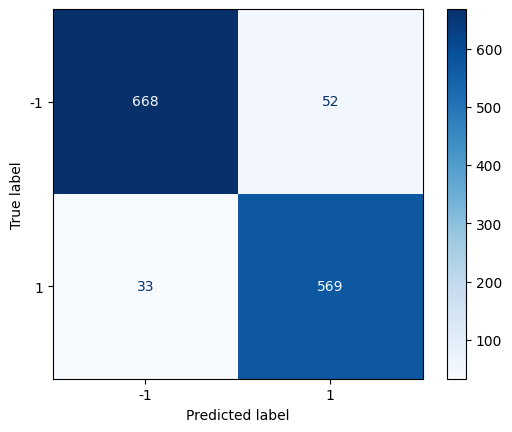

[[628  92]
 [366 236]]


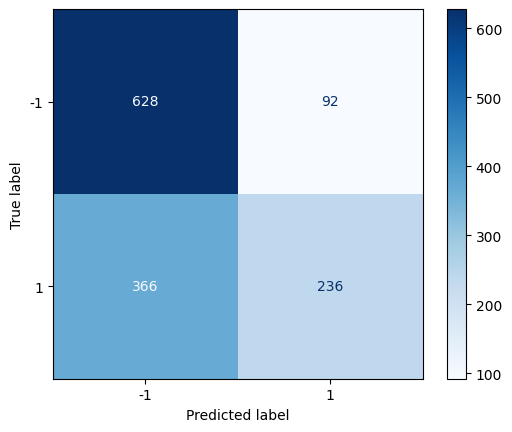

[[675  45]
 [ 39 563]]


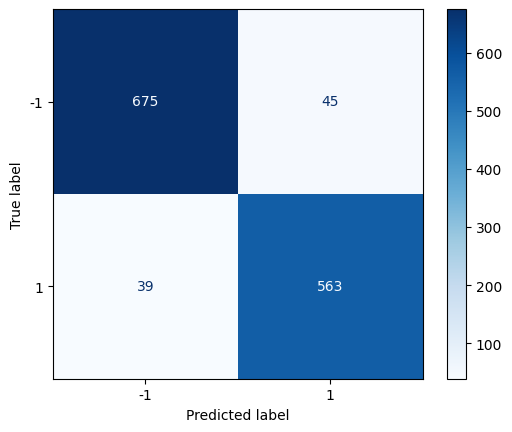

[[518 202]
 [116 486]]


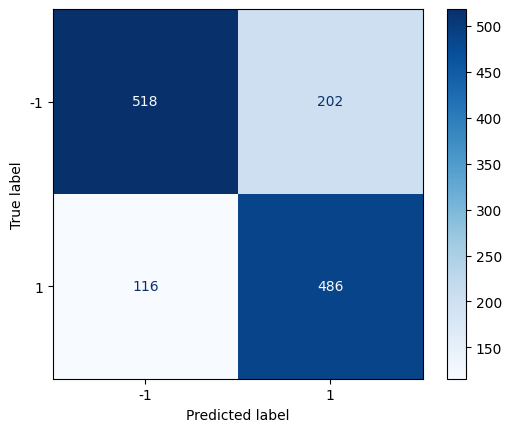

In [125]:
def conf_metric(model):
  y_pred = model.predict(X_test_scaled)

  # Membuat confusion matrix
  cm = confusion_matrix(y_test, y_pred, labels=[-1, 1])

  print(cm)

  # Visualisasi confusion matrix
  disp = ConfusionMatrixDisplay(
      confusion_matrix=cm,
      display_labels=[-1, 1]
  )
  disp.plot(cmap="Blues")
  plt.show()

conf_metric(p1)
conf_metric(p_model)
conf_metric(a1)
conf_metric(a_model)

Grafik Error/Loss Per Epoch untuk standar eta=0.01 untuk non standar eta=0.001

Standarisasi


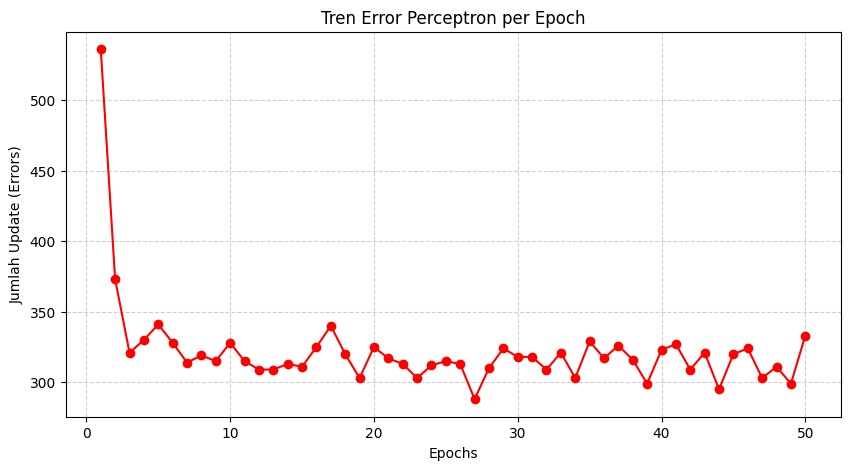

Tanpa Standarisasi


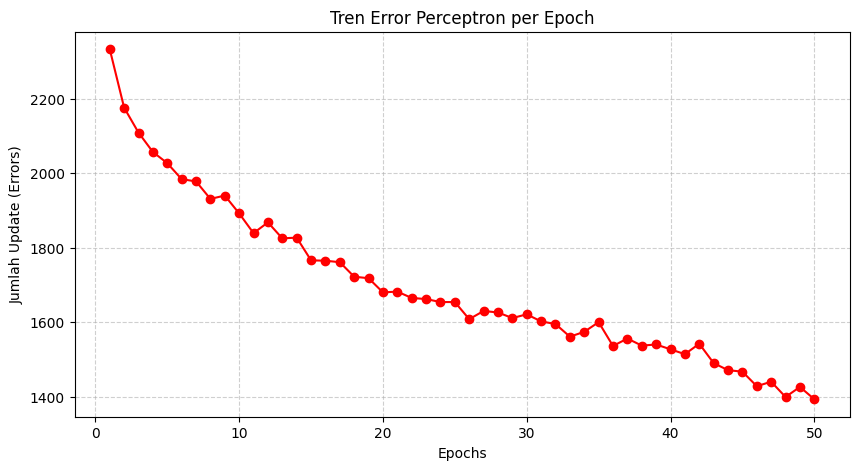

In [126]:
def plot_error(model):
  plt.figure(figsize=(10, 5))
  plt.plot(range(1, len(model.errors_) + 1), model.errors_, marker='o', color='red')
  plt.xlabel('Epochs')
  plt.ylabel('Jumlah Update (Errors)')
  plt.title('Tren Error Perceptron per Epoch')
  plt.grid(True, linestyle='--', alpha=0.6)
  plt.show()

print("Standarisasi")
plot_error(p1)
print("Tanpa Standarisasi")
plot_error(p_model)

Standarisasi


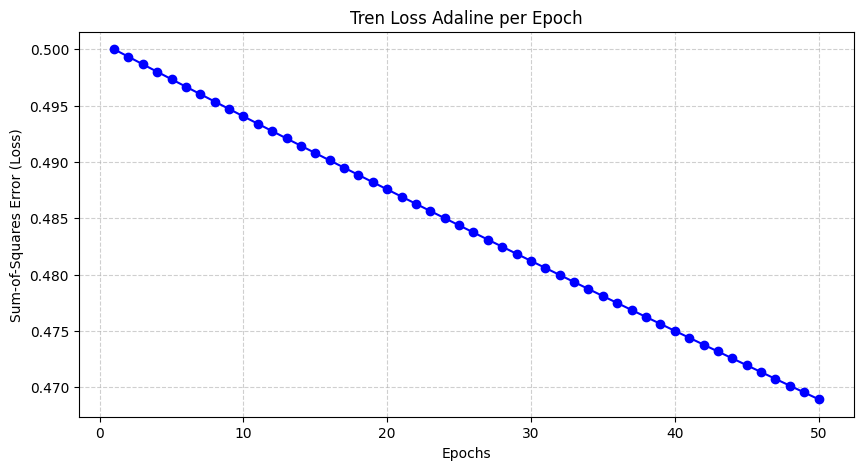

Tanpa Standarisasi


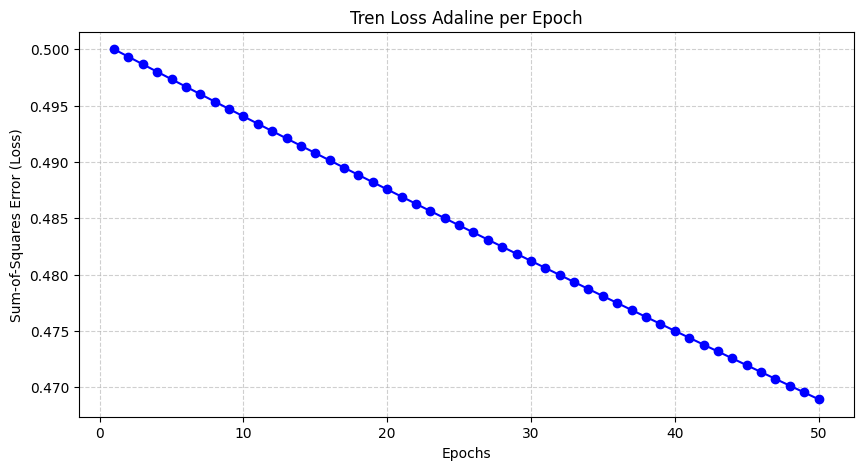

In [124]:
def plot_loss(model):
  plt.figure(figsize=(10, 5))
  plt.plot(range(1, len(a1.loss_) + 1), a1.loss_, marker='o', color='blue')
  plt.xlabel('Epochs')
  plt.ylabel('Sum-of-Squares Error (Loss)')
  plt.title('Tren Loss Adaline per Epoch')
  plt.grid(True, linestyle='--', alpha=0.6)
  plt.show()


print("Standarisasi")
plot_loss(a1)
print("Tanpa Standarisasi")
plot_loss(a_model)

Kesalahan Latih Setelah Epoch Terakhir

In [132]:
print(f'Perceptron Non Standar (eta=0.01) - Jumlah Update Error Terakhir: {p_model.errors_[-1]}')
print(f'Adaline Non Standar (eta=0.01) - Nilai MSE Loss Terakhir: {a_model.loss_[-1]:.6f}')
print(f'Perceptron (eta=0.001) - Jumlah Update Error Terakhir: {p1.errors_[-1]}')
print(f'Adaline (eta=0.001) - Nilai MSE Loss Terakhir: {a1.loss_[-1]:.6f}')

Perceptron Non Standar (eta=0.01) - Jumlah Update Error Terakhir: 1452
Adaline Non Standar (eta=0.01) - Nilai MSE Loss Terakhir: 18611906884884634501170707209982286796956883435713626339549735141625159371560735269226689735775337823035656042103132276950993436186885031974993180880562066446222183698469686605884010851124649872846749696.000000
Perceptron (eta=0.001) - Jumlah Update Error Terakhir: 333
Adaline (eta=0.001) - Nilai MSE Loss Terakhir: 0.468929
